In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
df=pd.DataFrame({
    'h':[150,160,170,180,190],
    'w':[50,60,70,80,90]
})
mean=df.mean()
print("Mean value are:",mean)
s=df.std()
print("Standardization are:",s)

z_score=(df-mean)/s


print(z_score.round(2))

Mean value are: h    170.0
w     70.0
dtype: float64
Standardization are: h    15.811388
w    15.811388
dtype: float64
      h     w
0 -1.26 -1.26
1 -0.63 -0.63
2  0.00  0.00
3  0.63  0.63
4  1.26  1.26


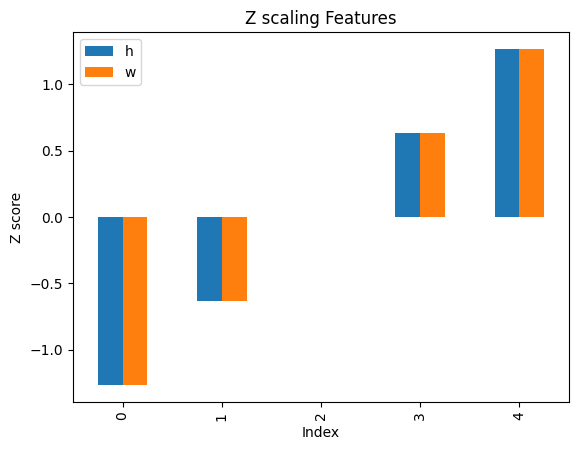

In [3]:
z_score.plot(kind='bar')
plt.title('Z scaling Features')
plt.xlabel("Index")
plt.ylabel("Z score")
plt.show()

# Min-Max Scaling

In [10]:
df=pd.DataFrame({
                'h':[150,160,175,180,190],
                'w':[50,60,70,80,90]})
df


,h,w
0,150,50
1,160,60
2,175,70
3,180,80
4,190,90


In [11]:
#Min max value
mn=df.min()
mx=df.max()
rng=mx-mn
rng,mn,mx

(h    40
 w    40
 dtype: int64,
 h    150
 w     50
 dtype: int64,
 h    190
 w     90
 dtype: int64)

In [12]:
#Formula x'=(x-min)/range
# x-min

ss=df-mn
ss

,h,w
0,0,0
1,10,10
2,25,20
3,30,30
4,40,40


In [13]:
#devidesion
mn=ss/rng
mn

,h,w
0,0.000,0.00
1,0.250,0.25
2,0.625,0.50
3,0.750,0.75
4,1.000,1.00


Text(0, 0.5, 'Min-Max Scale')

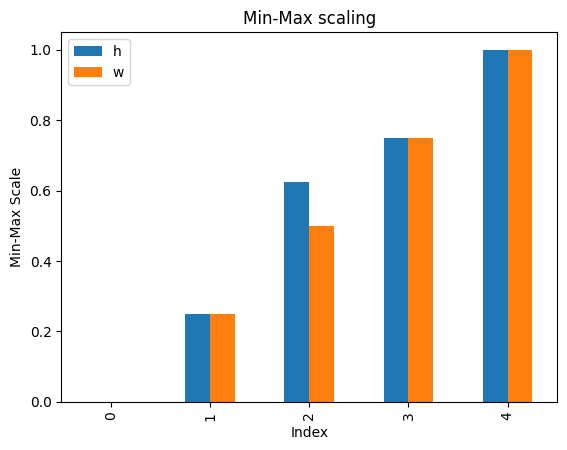

In [14]:
#create Plot
mn.plot(kind='bar')
plt.title('Min-Max scaling')
plt.xlabel('Index')
plt.ylabel('Min-Max Scale')

# Robust Scaling

In [16]:
df=pd.DataFrame({
                'h':[150,160,175,180,300],
                'w':[50,60,70,80,200]})
df

,h,w
0,150,50
1,160,60
2,175,70
3,180,80
4,300,200


In [17]:
md=df.median()
q1=df.quantile(.25)
q3=df.quantile(.75)
iqr=q3-q1
#x-median calculate
ss=df-md

#(x-median)/iqr

robust=ss/iqr

robust


,h,w
0,-1.25,-1.0
1,-0.75,-0.5
2,0.00,0.0
3,0.25,0.5
4,6.25,6.5


Text(0, 0.5, 'Robust Scaling')

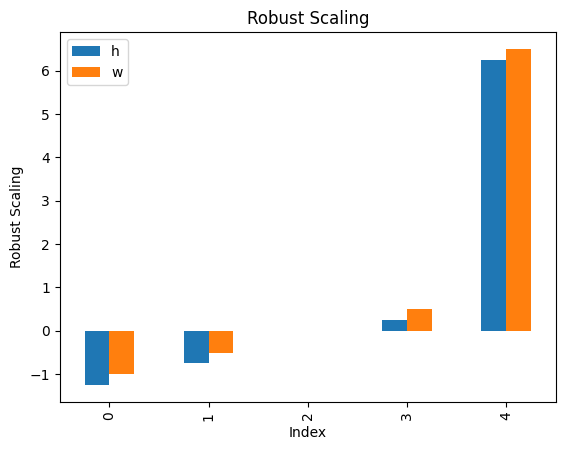

In [ ]:
# visualization
robust.plot(kind='bar')
plt.title("Robust Scaling")
plt.xlabel("Index")
plt.ylabel("Robust value")

In [21]:
#Comparision
#Standardization

m=df.mean()
s=df.std()
z=(df-m)/s

#Min Max 
mn=df.min()
mx=df.max()
mn=(df-mn)/(mx-mn)

out=pd.concat([df,z.add_prefix('z_'),mn.add_prefix('mm_'),robust.add_prefix('rb_')],axis=1)
out.round(2)

,h,w,z_h,z_w,mm_h,mm_w,rb_h,rb_w
0,150,50,-0.71,-0.68,0.00,0.00,-1.25,-1.0
1,160,60,-0.54,-0.52,0.07,0.07,-0.75,-0.5
2,175,70,-0.30,-0.36,0.17,0.13,0.00,0.0
3,180,80,-0.21,-0.20,0.20,0.20,0.25,0.5
4,300,200,1.75,1.76,1.00,1.00,6.25,6.5


# Nominal vs ordinal one hot encoding

In [2]:
df=pd.DataFrame({
    'id':[1,2,3,4],
    'color':['red','blue','green','red'],
    'size':['Small','Medium','Large','Medium'],
    'prices':[10,12,15,11]
})
df

,id,color,size,prices
0,1,red,Small,10
1,2,blue,Medium,12
2,3,green,Large,15
3,4,red,Medium,11


# Step 2 Apply one hot encoding to the color column


In [10]:
d_color=pd.get_dummies(df['color'],prefix='C',dtype=int)
d_color

,C_blue,C_green,C_red
0,0,0,1
1,1,0,0
2,0,1,0
3,0,0,1


In [11]:
# Combine the new columns back with the orginal data

df_encoded=pd.concat([df,d_color],axis=1)
df_encoded

,id,color,size,prices,C_blue,C_green,C_red
0,1,red,Small,10,0,0,1
1,2,blue,Medium,12,1,0,0
2,3,green,Large,15,0,1,0
3,4,red,Medium,11,0,0,1


In [12]:
# Step 4 Drop the old color coumn if you no longer need id
df_encoded=df_encoded.drop('color',axis=1)
print(df_encoded)

   id    size  prices  C_blue  C_green  C_red
0   1   Small      10       0        0      1
1   2  Medium      12       1        0      0
2   3   Large      15       0        1      0
3   4  Medium      11       0        0      1


In [13]:
df=pd.DataFrame({
    'id':[1,2,3,4],
    'color':['red','blue','green','red'],
    'size':['Small','Medium','Large','Medium'],
    'prices':[10,12,15,11]
})
df

,id,color,size,prices
0,1,red,Small,10
1,2,blue,Medium,12
2,3,green,Large,15
3,4,red,Medium,11


In [15]:
# step 2
order={'Small':1,'Medium':2,'Large':3}


In [16]:
#step 3
df['size_encoded']=df['size'].map(order).astype(int)
df

,id,color,size,prices,size_encoded
0,1,red,Small,10,1
1,2,blue,Medium,12,2
2,3,green,Large,15,3
3,4,red,Medium,11,2


# Understanding vectors Dot Product and Norms a hand on python exploration

In [3]:
#create  vector
a=np.array([1,2,3,4])
b=np.array([2,3,4,5])
print(a)
print(b)


[1 2 3 4]
[2 3 4 5]


In [4]:
# Step 2 : vector operations(Addition and Subtraction)
add_ab=a+b
sub_ab=a-b
print(add_ab)
print(sub_ab)

[3 5 7 9]
[-1 -1 -1 -1]


In [ ]:
#step 3 :Dot Product (similarity of direction)
#Mnual dot product: sum of pairwise products
dot=a@b# dot np.dot(a,b)
print(dot)

40


In [ ]:
#Step 4: Norms (Length or Magnitude of a vector)
#L2 norm, the usual length
l2_a=np.linalg.norm(a)#sqr(a**2+b**2+c**2)
print(l2_a)
l1_a=np.linalg.norm(a,ord=1)# all value summation
print(l1_a)

5.477225575051661
10.0


In [ ]:
#step 5:Normaliizing a vector (Unit vector)
unit_a=a/np.linalg.norm(a)#Unit vector
len_unit_a=np.linalg.norm(unit_a)#distance 
print(unit_a)
print(len_unit_a)

[0.18257419 0.36514837 0.54772256 0.73029674]
0.9999999999999999


# Euclidean Distance and Manhattan distance 


In [12]:
p=np.array([[70,80],
            [60,90],
            [85,60],
            [78,76],
            [62,65]])
q=np.array([75,70],dtype=float)
print("X Shape:",p.shape)
print("Q :",q.tolist())


X Shape: (5, 2)
Q : [75.0, 70.0]


In [13]:
#Euclidean Distance(L1)
eu=np.linalg.norm(p-q,axis=1)
print("Euclidean :",np.round(eu,3).tolist())

#Manhattan Dstance (L1)
ma=np.linalg.norm(p-q,ord=1,axis=1)
print("Manhattan:",ma.tolist())

Euclidean : [11.18, 25.0, 14.142, 6.708, 13.928]
Manhattan: [15.0, 35.0, 20.0, 9.0, 18.0]


# Practice problem solve

In [17]:
df=pd.DataFrame({
    'weight':[58,62,65],
    'height':[150,160,170]
})
mn=df.mean()
std=df.std()
ss=df-mn
std,mn
# z=ss/std
# print(z)
# z

(weight     3.511885
 height    10.000000
 dtype: float64,
 weight     61.666667
 height    160.000000
 dtype: float64)